# Test the implementation of the NFR.py file

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget

import FGVizHelpers as fgtools
from NFR import NFR, main

from pathlib import Path
import os
import copy
import gtsam
import time

np.set_printoptions(linewidth=np.inf, threshold=np.inf, suppress=True)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [4]:
# Load graph
plt.close('all')
directory = "../results/FinalProject/s1_medium/"
fileName = "fullSavedGraph.g2o"
graphPath = directory
orig_graph, orig_values= fgtools.readG2oWithPrior(graphPath + fileName, loadGPS=False)
graph, values, blocks, nfr = main(graphPath, "whole", block_width=10.0, vizualize=False)
orig_blocks = copy.deepcopy(blocks)
# fgtools.plot_graph(orig_graph, orig_values, title="Original Graph")


graphPath: ../results/FinalProject/s1_medium/
block_-1_1, smallCov: True
block_-1_-1, smallCov: True
block_-2_-1, smallCov: True
block_-3_-1, smallCov: True
block_-3_-2, smallCov: True
block_-4_-2, smallCov: True
block_-4_-3, smallCov: True
block_-4_-4, smallCov: True
block_-4_-5, smallCov: True
block_-4_-6, smallCov: True
block_-4_-7, smallCov: True
block_-4_-8, smallCov: True
block_-4_-9, smallCov: True
block_-3_-9, smallCov: True
block_-3_-10, smallCov: True
block_-3_-11, smallCov: True
block_-3_-12, smallCov: True
block_-3_-13, smallCov: True
block_-3_-14, smallCov: True
block_-3_-15, smallCov: True
block_-2_-15, smallCov: True
block_-2_-14, smallCov: True
block_-1_-14, smallCov: True
block_-1_-13, smallCov: True
block_-1_-12, smallCov: True
block_1_-12, smallCov: True
block_1_-11, smallCov: True
block_1_-10, smallCov: True
block_2_-10, smallCov: True
block_2_-9, smallCov: True
block_2_-8, smallCov: True
block_3_-7, smallCov: True
block_4_-7, smallCov: True
block_4_-6, smallCov: Tr

In [3]:
# nfr.PlotGraphDiff()

graph, values = fgtools.readG2oWithPrior("TestDir/sparseGraph.g2o", loadGPS=False)
marginals = gtsam.Marginals(graph, values)
for key in values.keys():
    print(f"Key: {key}, Marginal: {marginals.marginalCovariance(key)}")

Key: 0, Marginal: [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]]
Key: 1, Marginal: [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]]
Key: 2, Marginal: [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]]
Key: 3, Marginal: [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]]
Key: 4, Marginal: [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]]
Key: 5, Marginal: [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan n

In [11]:
# Load graph
fileName = "fullSavedGraph.g2o"
if graphPath is None:
    scriptDir = os.path.dirname(os.path.realpath(__file__))
    graphPath = os.path.join(scriptDir, "../results/second_session/")
    print(f"graphPath: {graphPath}")
    graph, values = fgtools.readG2oWithPrior(graphPath + fileName, loadGPS=False)
else:
    print(f"graphPath: {graphPath}")
    graph, values = fgtools.readG2oWithPrior(graphPath + fileName)




hasPrior = False
for i in range(graph.size()):
    f = graph.at(i)
    if isinstance(f, gtsam.PriorFactorPose3):
        hasPrior = True
        break
if not hasPrior:
    print("No prior factor detected in graph. Adding prior to first node.")
    firstKey = list(values.keys())[0]
    graph.add(gtsam.PriorFactorPose3(firstKey, values.atPose3(firstKey), gtsam.noiseModel.Diagonal.Sigmas(np.array([1e-6, 1e-6, 1e-6, 1e-6, 1e-6, 1e-6]))))

orig_optimizer = gtsam.LevenbergMarquardtOptimizer(graph, values)
values = orig_optimizer.optimize()

originalMarginals = gtsam.Marginals(graph, values)

# Defines the type of the dictionary instead of [any, any] so that Pylance can autofill and such
blocks: dict[str, fgtools.BlockStruct] = {}
# block_width = 50
blockKeyOrder = []

pose = {}
for i, key in enumerate(values.keys()):
    p = values.atPose3(key)

    # Calculate which cell the pose is in
    cell, dist_to_center = fgtools.getBlockCell(p.x(), p.y())
    if i == 0:
        secondPose = values.atPose3(list(values.keys())[1]) # Put the first pose in the same cell as the second pose.
        if np.linalg.norm(np.array([secondPose.x() - p.x(), secondPose.y() - p.y()])) < 5.:
            cell, _ = fgtools.getBlockCell(secondPose.x(), secondPose.y())
            print(f"Warning: The first two poses are not in the same cell. This may cause issues with the block structure. First pose: ({p.x()}, {p.y()}), Second pose: ({secondPose.x()}, {secondPose.y()})")

    # Create the block 'key' based on grid location
    block_key = fgtools.getBlockKey([cell.x, cell.y])
    if not blockKeyOrder or blockKeyOrder[-1] != block_key:
        blockKeyOrder.append(block_key)
        
    # Update poses and closest to center pose
    if block_key in blocks:
        poses, closestDist, poseKey = blocks[block_key].poses, blocks[block_key].closestDist, blocks[block_key].poseKey
        if (dist_to_center < closestDist):
            closestDist = dist_to_center
            poseKey = key
    else:
        poses = {}
        closestDist = dist_to_center
        poseKey = key
    poses[key] = p
    
    blocks[block_key] = fgtools.BlockStruct(poses, closestDist, poseKey, block_key, cell)

    # break
internalThreshold = fgtools.ThresholdStruct(0.05, 0.05, 0.05)
globalThreshold = fgtools.ThresholdStruct(0.1, 0.1, 0.50)




graphPath: ../results/second_session/


In [12]:
for block_key in blocks.keys():
    print(f"{block_key}")
    print(f"  {list(blocks[block_key].poses.keys())}")

block_-1_-3
  [0, 856, 857, 858, 859, 860, 861, 862, 863, 864, 865, 866, 867, 868, 869, 870, 871, 872, 873, 874, 875, 876, 877, 878, 879, 880, 881, 882, 883, 884, 885, 886, 887, 888, 889, 890, 891, 892, 893, 894, 895, 896, 897, 898, 899, 900, 901, 902, 903, 904]
block_1_-3
  [1, 812, 813, 814, 815, 816, 817, 818, 819, 820, 821, 822, 823, 824, 825, 826, 827, 828, 829, 830, 831, 832, 833, 834, 835, 836, 837, 838, 839, 840, 841, 842, 843, 844, 845, 846, 847, 848, 849, 850, 851, 852, 853, 854, 855]
block_1_-2
  [2, 725, 726, 727, 728, 729, 730, 731, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744, 745, 746, 747, 748, 749, 750, 751, 752, 947, 948, 949, 950, 951, 952, 953, 954, 955, 956, 957, 958, 959, 960, 961, 962, 963, 964, 965, 966, 967, 968, 969, 970, 971, 972, 973, 974, 975, 976, 977, 978, 979, 980, 981, 982, 983, 984, 985, 986, 987, 988, 989, 990, 991, 992, 993, 994, 995, 996, 997, 998, 999, 1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009]
block_1_-1
  [3, 6

In [14]:
for block_key in blocks.keys():
    smallCov = fgtools.isBlockCovSmall(originalMarginals, blocks[block_key].poses, internalThreshold, globalThreshold)
    blocks[block_key].smallCov = smallCov
    print(f"{block_key}, smallCov: {smallCov}")

Relative covariance too big between keys "904" and "856"
relVal > Threshold
x: 0.0011892139209502338 > 0.0002777777777777778 -> True
y: 0.0005353507159216801 > 0.0002777777777777778 -> True
z: 2.0620870781456384e-05 > 0.0002777777777777778 -> False
det: 1.280489865713794e-11 > 2.1433470507544654e-11 -> False
block_-1_-3, smallCov: False
Relative covariance too big between keys "855" and "1"
relVal > Threshold
x: 0.000454032089620458 > 0.0002777777777777778 -> True
y: 0.0007725265082738018 > 0.0002777777777777778 -> True
z: 3.413339532366659e-05 > 0.0002777777777777778 -> False
det: 1.0797768543181158e-11 > 2.1433470507544654e-11 -> False
block_1_-3, smallCov: False
Relative covariance too big between keys "1009" and "2"
relVal > Threshold
x: 0.000376733112585296 > 0.0002777777777777778 -> True
y: 0.0005272772625293412 > 0.0002777777777777778 -> True
z: 1.9304454721971167e-05 > 0.0002777777777777778 -> False
det: 3.6169771237042403e-12 > 2.1433470507544654e-11 -> False
block_1_-2, small

In [ ]:
pcds = fgtools.loadPosePCDs(directory + "Scans/")
block_pcds, non_block_pcds = fgtools.combinePCDsInBlocks(blocks, pcds, orig_values)

In [3]:
# Visualize block_pcds all at once
import open3d as o3d

directory = "SparseGraphNFR/"
graph, values = fgtools.readG2oWithPrior(directory + "sparseGraph.g2o", loadGPS=False)
block_pcds = fgtools.loadBlockPCDs(directory + "blocks/")
non_block_pcds = fgtools.loadPosePCDs(directory + "non_blocks/")
block2pose_mapping = fgtools.loadPose2BlockMapping(directory + "pose2block_mapping.txt", reverse=True)

global_pcd = o3d.geometry.PointCloud()
for blockKey in block_pcds:
    block_pcd = copy.deepcopy(block_pcds[blockKey])
    block_pcd.transform(values.atPose3(block2pose_mapping[blockKey]).matrix())
    global_pcd += block_pcd
for poseKey in non_block_pcds:
    pcd = copy.deepcopy(non_block_pcds[poseKey])
    pcd.transform(values.atPose3(poseKey).matrix())
    global_pcd += pcd
o3d.visualization.draw_geometries([global_pcd])

In [8]:
print(f"Orig Graph Keys: {graph.keys()}")
print(f"Orig Value Keys: {values.keys()}")

poseKeys = [blocks[blockKey].poseKey for blockKey in blocks]
print(f"Orig Block PoseKeys: {poseKeys}")
new_graph, new_values, pose2block_mapping, key_mapping = fgtools.rekeyGraphAndBlocks(graph, values, blocks)

print(f"\nNew Graph Keys: {new_graph.keys()}")
print(f"New Value Keys: {new_values.keys()}")
new_poseKeys = [blocks[blockKey].poseKey for blockKey in blocks]
print(f"New Block PoseKeys: {new_poseKeys}")
print(f"Pose2Block Mapping: {pose2block_mapping}")

Orig Graph Keys: 13419323529534740358461969674278391794697810241069112411841229127813261369141414611487149515241566161016501678171317441771179817991800180118021803180418051806180718081809181018111812181318141815181618171818181918201821182218231824182518261827182818291830183118321833183418351836183718381839184018411842184318441845184618471848184918501851185218531854185518561857185818591860186118621863186418651866186718681869187018711872187318741875187618771878187918801881188218831884188518861887188818891890189118921893189418951896189718981899190019011902190319041905190619071908190919101911191219131914191519161917191819191920192119221923192419251926192719281929193019311932193319341935193619371938193919401941194219431944194519461947194819491950195119521953195419551956195719581959196019611962196319641965196619671968196919701971197219731974197519761977197819791980198119821983198419851986198719881989199019911992199319941995199619971998199920002001200220032004200520062007200820092010201120122

In [ ]:
pose2block_mapping

In [12]:
fgtools.savePointClouds(block_pcds, non_block_pcds, "TestBlocks", pose2block_mapping,key_mapping, removeExisting=True)

In [31]:
marginal = gtsam.Marginals(nfr.initial_graph, nfr.initial_values)
marginal_after = gtsam.Marginals(nfr.graph, nfr.values)
key = nfr.values.keys()[0]
cov1 = marginal.marginalCovariance(key)
cov2 = marginal_after.marginalCovariance(key)
print(f"\nKey: {key}")
print("cov1:\n", cov1)
print("cov2:\n", cov2)


Key: 166
cov1:
 [[ 0.0001516  -0.00001226 -0.00000011  0.00000281 -0.00003133  0.00708263]
 [-0.00001226  0.00016807 -0.0000006   0.00003387 -0.00000149 -0.01026808]
 [-0.00000011 -0.0000006   0.00005428 -0.00173311  0.00251898  0.00002128]
 [ 0.00000281  0.00003387 -0.00173311  0.33136392 -0.10772507 -0.0006688 ]
 [-0.00003133 -0.00000149  0.00251898 -0.10772507  0.45798442 -0.00141072]
 [ 0.00708263 -0.01026808  0.00002128 -0.0006688  -0.00141072  1.41943382]]
cov2:
 [[nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]
 [nan nan nan nan nan nan]]


In [23]:
fgtools.checkConservitiveness(nfr.initial_graph, nfr.initial_values, nfr.graph, nfr.values)


Key: 1537
Is PSD as per numpy cholesky
Matrix is not PSD because it is not Hermitian
Matrix is not PSD because it is not Hermitian
cov1:
 [[nan nan]
 [nan nan]]
cov2:
 [[ 0.00013423 -0.00001215]
 [-0.00001215  0.00007863]]
PSD: rp  False
Matrix is not PSD because it is not Hermitian
cov1:
 [[nan nan]
 [nan nan]]
cov2:
 [[ 0.00007863 -0.00000017]
 [-0.00000017  0.00005021]]
PSD: py False
Matrix is not PSD because it is not Hermitian
cov1:
 [[nan]]
cov2:
 [[0.00007863]]
PSD: ry  False
Matrix is not PSD because it is not Hermitian
cov1:
 [[nan nan]
 [nan nan]]
cov2:
 [[0.44292052 0.04223857]
 [0.04223857 0.37744275]]
PSD: xy  False
Matrix is not PSD because it is not Hermitian
cov1:
 [[nan nan]
 [nan nan]]
cov2:
 [[0.37744275 0.00327769]
 [0.00327769 0.92935376]]
PSD: yz  False
Matrix is not PSD because it is not Hermitian
cov1:
 [[nan nan]
 [nan nan]]
cov2:
 [[ 0.44292052 -0.00096925]
 [-0.00096925  0.92935376]]
PSD: xz  False

Key: 1793
Is PSD as per numpy cholesky
Matrix is not PSD be

True

In [10]:
hf = gtsam.HessianFactor()
gfg = graph.linearize(values)
for i in range(gfg.size()):
    f = gfg.at(i)
    if len(f.keys()) > 2:
        hf = f
    # hf = f
    # break


In [11]:
hf.keys()

[43, 89, 235, 294, 402, 583]

[43, 89, 235, 294, 402, 583]
Eigval rank calc time:  0.0003898143768310547
Np rank calc time:  0.00010347366333007812
ranks: 36 vs 36
eigen values:  [141694.85467534 127311.86196804  68154.09155479  75177.35133226  73637.96992696  59571.32888457  54113.97280986  51597.47845216  48424.23036023  46504.6283854   43839.3620272   36910.36211788  31418.91545268  30894.41511432  13322.79012844  11324.56034272   9553.85255085    883.52911296    545.92164467    244.23699197    223.04703296    102.90633611     91.60828165     85.30803697     37.04031536     27.86005929     20.23803491      6.90537296      5.53998802      5.96859829      3.43462914      2.17668678      1.10234787      0.40725996      0.01926613      0.15592215]
det:  5.864140325943517e+99
Adding unary to root 43
(235, 294)
(583, 235)
(43, 89)
(43, 402)
(402, 583)
(43, None)

Key: 192
condition num of cov1:  49977.552939709
condition num of cov2:  37392.1115777351
Not PSD as per numpy cholesky
Smallest eigenvalue is not positive: 

True

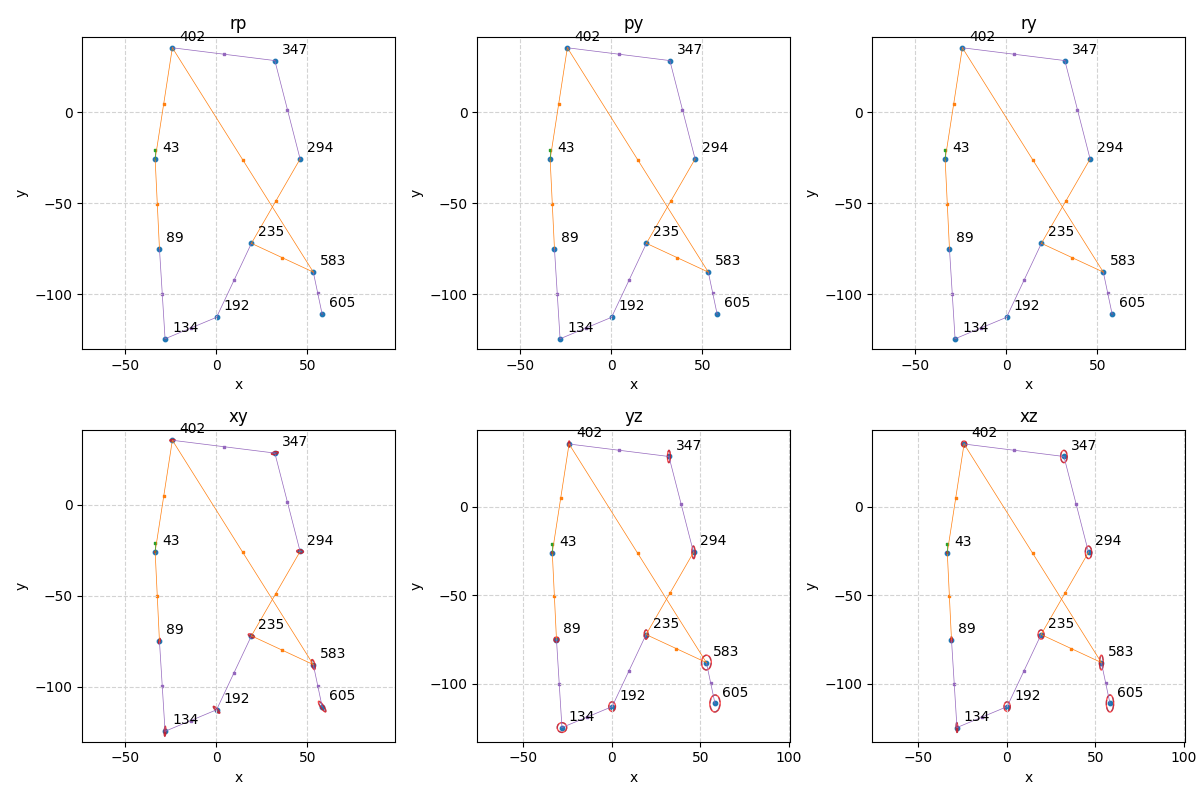

In [58]:
plt.close('all')
new_graph = copy.deepcopy(graph)
new_values = copy.deepcopy(values)

factorsToAdd = NFR.TreeNFR(hf, new_values)

tmpGraph = gtsam.NonlinearFactorGraph()

for i in range(new_graph.size()):
    f = graph.at(i)
    if tuple(f.keys()) != tuple(hf.keys()):
        tmpGraph.add(f)

new_graph = tmpGraph

for f in factorsToAdd:
    new_graph.add(f)



# new_optimizer = gtsam.LevenbergMarquardtOptimizer(new_graph, new_values)
# new_values = new_optimizer.optimize()

subsets = ['rp', 'py', 'ry', 'xy', 'yz', 'xz', ]
fig, axes = plt.subplots(2, 3, figsize=(3*4, 2*4))
axes = axes.flatten()
for ax, subset in zip(axes, subsets):
    fgtools.plot_graph(new_graph, new_values, addKeyLabels=True, ax=ax, title=subset)
    fgtools.plot_graph_covariances(new_values.keys(), graph, values, ax, subset=subset, edgecolor='tab:blue', linestyle="--", alpha=0.7)
    fgtools.plot_graph_covariances(new_values.keys(), new_graph, new_values, ax, subset=subset, edgecolor='red', alpha=0.7)
plt.tight_layout()
    
# plt.xlim([45, 65])
# plt.ylim([-95, -75])

fgtools.checkConservitiveness(graph, values, new_graph, new_values)

In [36]:
sigFigs = lambda x: float(f"{x:.6g}")


sigFigs(1245879)

1245880.0

True

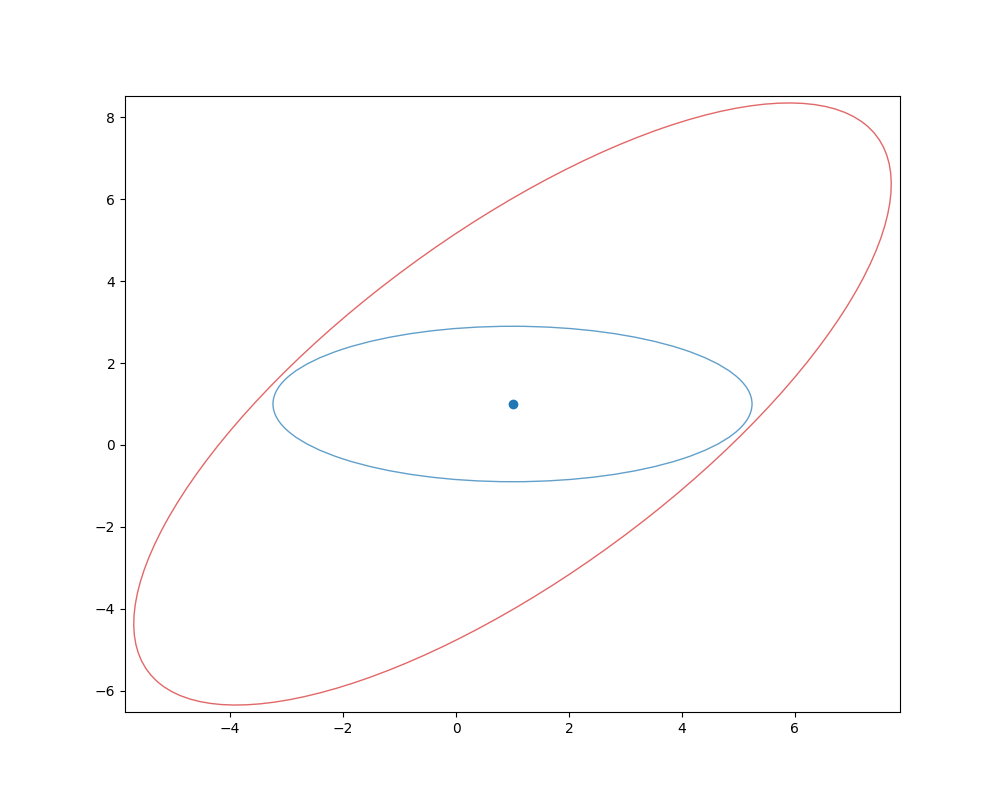

In [21]:
cov1 = np.array([[5., 4.],[4., 6.]])
cov2 = 0.4 * np.array([[5., 0.],[0., 1.]])
# cov2 = 1.001 * cov1.copy()

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(1, 1)
fgtools.covariance_ellipse(1., 1., cov1, ax, edgecolor='tab:red')
fgtools.covariance_ellipse(1., 1., cov2, ax, )

fgtools.isPSD(cov1 - cov2)

In [45]:
m1 = np.array([[1, 2, 3],
               [4, 5, 6],
               [7, 8, 9]])
m2 = m1.copy().T
print(m1)
print(m2)
m = np.stack([m1, m2])
m.shape
m_max = m.min(axis=0)
m_max

[[1 2 3]
 [4 5 6]
 [7 8 9]]
[[1 4 7]
 [2 5 8]
 [3 6 9]]


array([[1, 2, 3],
       [2, 5, 6],
       [3, 6, 9]])

In [4]:
dir(gtsam.GPSFactor)

['__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '_pybind11_conduit_v1_',
 'active',
 'clone',
 'deserialize',
 'dim',
 'empty',
 'equals',
 'error',
 'evaluateError',
 'keys',
 'linearize',
 'measurementIn',
 'print',
 'printKeys',
 'rekey',
 'serialize',
 'size']